<a href="https://colab.research.google.com/github/apoorvsrivastav433-dev/E-Commerce-Sales-Analytics-Customer-Segmentation-Predictive-Modeling/blob/main/E_Commerce_Sales_Analytics%2C_Customer_Segmentation_%26_Predictive_Modeling_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from google.colab import files

plt.style.use('seaborn-v0_8-whitegrid')

REQUIRED_FILES = ['orders.csv', 'payments.csv', 'products.csv', 'customers.csv']
missing_files = [f for f in REQUIRED_FILES if not os.path.exists(f)]

if missing_files:
    print("Missing files in current directory:", missing_files)
    print("Please upload the missing CSV files:")
    files.upload()
else:
    print("All required CSV files are ready in the current directory.")

Missing files in current directory: ['orders.csv', 'payments.csv', 'products.csv', 'customers.csv']
Please upload the missing CSV files:


Saving payments.csv to payments.csv
Saving products.csv to products.csv
Saving customers.csv to customers.csv
Saving orders.csv to orders.csv


In [23]:
orders = pd.read_csv('orders.csv')
payments = pd.read_csv('payments.csv')
products = pd.read_csv('products.csv')
customers = pd.read_csv('customers.csv')

# 2. Clean orders
orders_clean = orders.drop_duplicates(subset=['OrderID']).copy()
orders_clean = orders_clean.dropna(subset=['OrderDate', 'Quantity'])
orders_clean = orders_clean[orders_clean['Quantity'] > 0]

orders_clean['Discount'] = (
    orders_clean['Discount']
    .fillna(0.0)
    .clip(lower=0.0, upper=1.0)
)

mode_payment = orders_clean['PaymentMethod'].mode()
default_payment = mode_payment.iloc[0] if not mode_payment.empty else 'Unknown'
orders_clean['PaymentMethod'] = orders_clean['PaymentMethod'].fillna(default_payment)

orders_clean['OrderDate'] = pd.to_datetime(orders_clean['OrderDate'], errors='coerce')
orders_clean = orders_clean.dropna(subset=['OrderDate'])

# 3. Clean customers
customers_clean = customers.drop_duplicates(subset=['CustomerID']).copy()
customers_clean['City'] = (
    customers_clean['City']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
    .str.title()
    .replace({'Mashad': 'Mashhad'})
)
customers_clean['Age'] = customers_clean['Age'].fillna(customers_clean['Age'].median())
customers_clean['SignupDate'] = pd.to_datetime(customers_clean['SignupDate'], errors='coerce')

# 4. Clean payments
payments_clean = payments.drop_duplicates(subset=['OrderID']).copy()
payments_clean['PaymentDate'] = pd.to_datetime(payments_clean['PaymentDate'], errors='coerce')

# 5. Merge tables and engineer features
df = (
    orders_clean
    .merge(customers_clean, on='CustomerID', how='inner')
    .merge(products, on='ProductID', how='inner')
    .merge(payments_clean[['OrderID', 'PaymentStatus', 'PaymentDate']], on='OrderID', how='left')
)

df['GrossAmount'] = df['Quantity'] * df['UnitPrice']
df['NetSales'] = (df['GrossAmount'] * (1 - df['Discount'])).round(2)
df['OrderMonth'] = df['OrderDate'].dt.to_period('M').astype(str)
df['TenureDays'] = (df['OrderDate'] - df['SignupDate']).dt.days.clip(lower=0).fillna(0)

print(f"Cleaned dataset ready! Total rows: {df.shape[0]}, columns: {df.shape[1]}")

Cleaned dataset ready! Total rows: 49830, columns: 21


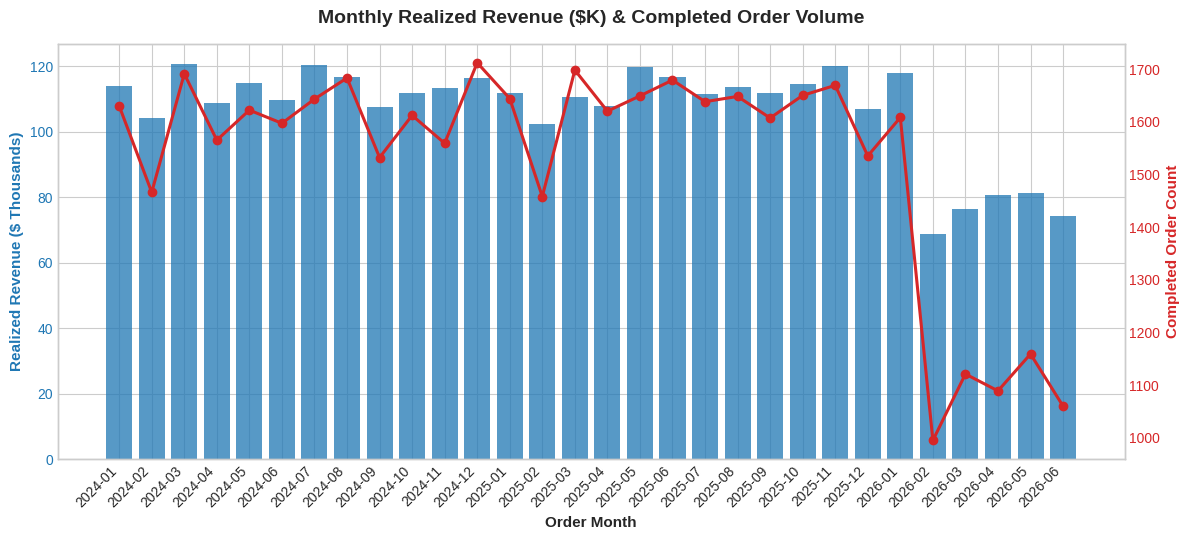

In [24]:
monthly = df[df['Status'] == 'Completed'].groupby('OrderMonth').agg(
    Revenue=('NetSales', 'sum'),
    Orders=('OrderID', 'count')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5.5))
color1 = '#1f77b4'
ax1.bar(monthly['OrderMonth'], monthly['Revenue'] / 1000, color=color1, alpha=0.75, label='Realized Revenue ($K)')
ax1.set_xlabel('Order Month', fontsize=11, fontweight='bold')
ax1.set_ylabel('Realized Revenue ($ Thousands)', color=color1, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
plt.xticks(rotation=45, ha='right')

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.plot(monthly['OrderMonth'], monthly['Orders'], color=color2, marker='o', linewidth=2.2, label='Completed Orders')
ax2.set_ylabel('Completed Order Count', color=color2, fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False)

plt.title('Monthly Realized Revenue ($K) & Completed Order Volume', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig('01_monthly_revenue_trend.png', dpi=150)
plt.show()

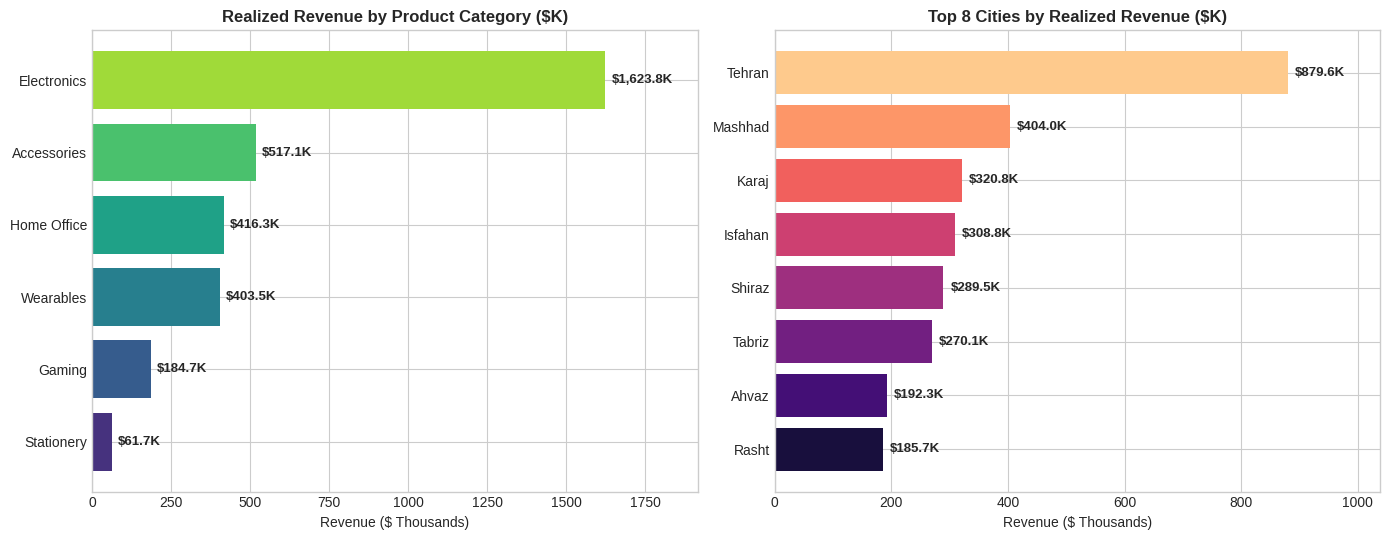

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: Category Revenue
cat_rev = df[df['Status'] == 'Completed'].groupby('Category')['NetSales'].sum().sort_values(ascending=True)
axes[0].barh(cat_rev.index, cat_rev.values / 1000, color=sns.color_palette('viridis', len(cat_rev)))
axes[0].set_title('Realized Revenue by Product Category ($K)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue ($ Thousands)')
for i, v in enumerate(cat_rev.values / 1000):
    axes[0].text(v + 20, i, f'${v:,.1f}K', va='center', fontsize=9.5, fontweight='bold')
axes[0].set_xlim(0, max(cat_rev.values / 1000) * 1.18)

# Right Panel: Top 8 Cities Revenue
city_rev = df[df['Status'] == 'Completed'].groupby('City')['NetSales'].sum().sort_values(ascending=True).tail(8)
axes[1].barh(city_rev.index, city_rev.values / 1000, color=sns.color_palette('magma', len(city_rev)))
axes[1].set_title('Top 8 Cities by Realized Revenue ($K)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Revenue ($ Thousands)')
for i, v in enumerate(city_rev.values / 1000):
    axes[1].text(v + 12, i, f'${v:,.1f}K', va='center', fontsize=9.5, fontweight='bold')
axes[1].set_xlim(0, max(city_rev.values / 1000) * 1.18)

plt.tight_layout()
plt.savefig('02_category_city_breakdown.png', dpi=150)
plt.show()

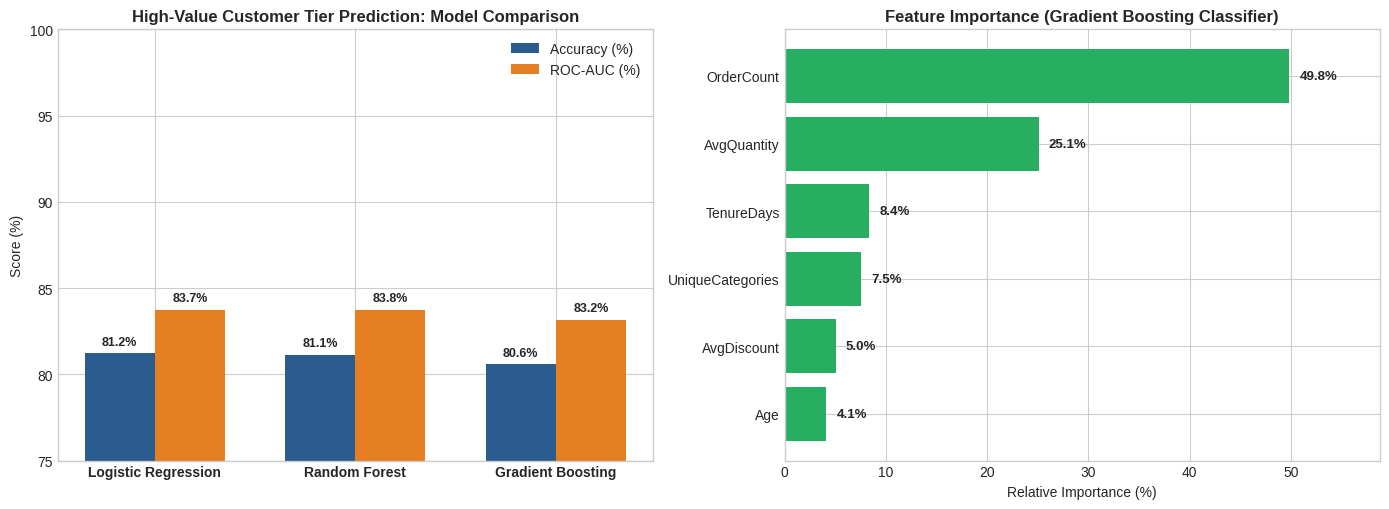

In [26]:
# Customer-level aggregation for High-Value Tier prediction
cust_agg = df[df['Status'] == 'Completed'].groupby('CustomerID').agg(
    TotalSpend=('NetSales', 'sum'),
    OrderCount=('OrderID', 'count'),
    AvgDiscount=('Discount', 'mean'),
    AvgQuantity=('Quantity', 'mean'),
    UniqueCategories=('Category', 'nunique'),
    TenureDays=('TenureDays', 'max'),
    Age=('Age', 'first')
).reset_index()

cust_agg['HighValueTier'] = (cust_agg['TotalSpend'] >= cust_agg['TotalSpend'].quantile(0.75)).astype(int)

features = ['OrderCount', 'AvgDiscount', 'AvgQuantity', 'UniqueCategories', 'TenureDays', 'Age']
X = cust_agg[features]
y = cust_agg['HighValueTier']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=4, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'ROC_AUC': roc_auc_score(y_test, probs)
    })

gb = models['Gradient Boosting']
importances = pd.Series(gb.feature_importances_, index=features).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
res_df = pd.DataFrame(results)
x_idx = np.arange(len(res_df))
width = 0.35

# Left Panel: Accuracy & ROC-AUC
axes[0].bar(x_idx - width / 2, res_df['Accuracy'] * 100, width, label='Accuracy (%)', color='#2b5c8f')
axes[0].bar(x_idx + width / 2, res_df['ROC_AUC'] * 100, width, label='ROC-AUC (%)', color='#e67e22')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(res_df['Model'], fontweight='bold')
axes[0].set_ylim(75, 100)
axes[0].set_ylabel('Score (%)')
axes[0].set_title('High-Value Customer Tier Prediction: Model Comparison', fontsize=12, fontweight='bold')
axes[0].legend()
for i, r in res_df.iterrows():
    axes[0].text(i - width / 2, r['Accuracy'] * 100 + 0.5, f"{r['Accuracy'] * 100:.1f}%", ha='center', fontsize=9, fontweight='bold')
    axes[0].text(i + width / 2, r['ROC_AUC'] * 100 + 0.5, f"{r['ROC_AUC'] * 100:.1f}%", ha='center', fontsize=9, fontweight='bold')

# Right Panel: Feature Importance
axes[1].barh(importances.index, importances.values * 100, color='#27ae60')
axes[1].set_title('Feature Importance (Gradient Boosting Classifier)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Relative Importance (%)')
for i, v in enumerate(importances.values * 100):
    axes[1].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=9.5, fontweight='bold')
axes[1].set_xlim(0, max(importances.values * 100) * 1.18)

plt.tight_layout()
plt.savefig('03_predictive_model_performance.png', dpi=150)
plt.show()